# Étape 1 — Exploration des données

**Termes techniques :** Image, pixel, RGB, dimensions, classe, label, distribution, dataset


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
from IPython.display import display

PROJECT_DIR = Path("../").resolve()
TRAIN_DIR   = PROJECT_DIR / "data" / "raw" / "seg_train"
PRED_DIR    = PROJECT_DIR / "data" / "raw" / "seg_pred"
CLASSES     = ["buildings", "forest", "glacier", "mountain", "sea", "street"]

print("seg_train:", TRAIN_DIR.exists())
print("seg_pred :", PRED_DIR.exists())
print("Classes  :", [d.name for d in sorted(TRAIN_DIR.iterdir())
                      if d.is_dir()])

seg_train: True
seg_pred : True
Classes  : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


## 1. Compter les images par classe

**Termes techniques :** Image, pixel, RGB, dimensions, classe, label, distribution, dataset


In [2]:
IMAGE_EXTENSIONS = [".jpg", ".jpeg", ".png", ".bmp", ".tiff", ".webp"]

class_counts = {}

for class_dir in TRAIN_DIR.iterdir():
    if class_dir.is_dir():
        images = [
            image for image in class_dir.iterdir()
            if image.is_file() and image.suffix.lower() in IMAGE_EXTENSIONS
        ]

        class_counts[class_dir.name] = len(images)

df_counts = pd.DataFrame(
    list(class_counts.items()),
    columns=["Classe", "Nombre d'images"]
)

# df_counts = df_counts.sort_values(
#     by="Nombre d'images",
#     ascending=False
# ).reset_index(drop=True)

print(df_counts)
print("\nNombre de classes :", len(df_counts))
print("Nombre total d'images :", df_counts["Nombre d'images"].sum())

      Classe  Nombre d'images
0  buildings             2628
1     forest             2745
2    glacier             2957
3   mountain             3037
4        sea             2784
5     street             2883

Nombre de classes : 6
Nombre total d'images : 17034


## 2. Visualiser plusieurs exemples par classe


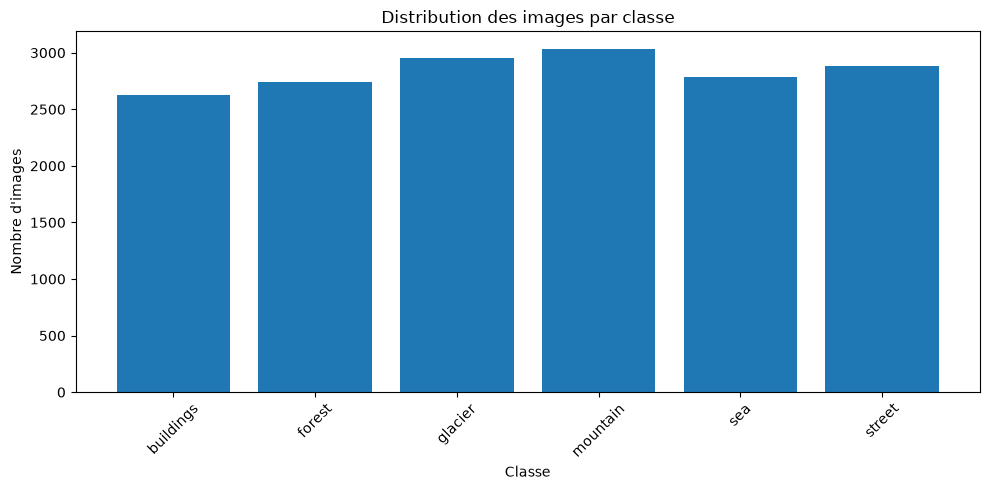

In [3]:
plt.figure(figsize=(10, 5))

plt.bar(
    df_counts["Classe"],
    df_counts["Nombre d'images"]
)

plt.title("Distribution des images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Vérifier dimensions et formats


In [4]:
image_info = []

for class_dir in TRAIN_DIR.iterdir():
    if class_dir.is_dir():
        for image_path in class_dir.iterdir():
             if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                try:
                    with Image.open(image_path) as img:
                        width, height = img.size
                        image_info.append({
                            "Classe": class_dir.name,
                            "Nom de l'image": image_path.name,
                            "Largeur": img.width,
                            "Hauteur": img.height,
                            "format": img.format,
                            "Mode": img.mode
                        })
                except Exception as e:
                    pass

df_images=pd.DataFrame(image_info)
print(df_images.head(10))
print("\nNombre total d'images :", len(df_images))


      Classe Nom de l'image  Largeur  Hauteur format Mode
0  buildings          0.jpg      150      150   JPEG  RGB
1  buildings      10006.jpg      150      150   JPEG  RGB
2  buildings       1001.jpg      150      150   JPEG  RGB
3  buildings      10014.jpg      150      150   JPEG  RGB
4  buildings      10018.jpg      150      150   JPEG  RGB
5  buildings      10029.jpg      150      150   JPEG  RGB
6  buildings      10032.jpg      150      150   JPEG  RGB
7  buildings      10056.jpg      150      150   JPEG  RGB
8  buildings       1009.jpg      150      150   JPEG  RGB
9  buildings      10113.jpg      150      150   JPEG  RGB

Nombre total d'images : 17034


## Repérer les images de dimensions anormales


In [5]:

small_images = df_images[
    (df_images["Largeur"] < 32) |
    (df_images["Hauteur"] < 32)
]

print("Images de dimensions inférieures à 32 pixels :")

columns_to_show = [
    col for col in ["Classe", "Nom", "Largeur", "Hauteur"]
    if col in small_images.columns
]

print(small_images[columns_to_show])
print("\nNombre d'images très petites :", len(small_images))


Images de dimensions inférieures à 32 pixels :
Empty DataFrame
Columns: [Classe, Largeur, Hauteur]
Index: []

Nombre d'images très petites : 0
